In [28]:
!pip install natsort
!pip install trimesh

   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---------------------------------------- 0.0/704.8 kB ? eta -:--:--
   ---

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
import numpy as np
from skimage import io
from skimage import measure
from natsort import natsorted
import matplotlib.pyplot as plt
from skimage.color import rgb2gray
from collections import defaultdict
import os

In [3]:
folder_path = os.path.join(os.getcwd(), "dataset_train")
dataset_folder = os.path.join(os.getcwd(), "dataset")
input_folder_path = os.path.join(folder_path, 'input')
output_folder_path = os.path.join(folder_path, 'output')
dataset_csv = os.path.join(folder_path, "data.csv")

In [66]:
image_dir = os.path.join(dataset_folder,"TCGA_CS_4941_19960909")
file_list = natsorted([f for f in os.listdir(image_dir) if f.endswith('.tif')])
for file in file_list:
    if file.find("_mask") >0:
        unique_id = file.split('_')[2]
    
        img_path = os.path.join(image_dir, file)
        img = io.imread(img_path)
    
        if img.ndim == 3 and img.shape[-1] == 3:
            img = rgb2gray(img)
    
        grouped_slices[unique_id].append(img)
        
for key, slices in grouped_slices.items():
    print(f"ID: {key}, Number of slices: {len(slices)}")

['TCGA_CS_4941_19960909_1.tif', 'TCGA_CS_4941_19960909_1_mask.tif', 'TCGA_CS_4941_19960909_2.tif', 'TCGA_CS_4941_19960909_2_mask.tif', 'TCGA_CS_4941_19960909_3.tif', 'TCGA_CS_4941_19960909_3_mask.tif', 'TCGA_CS_4941_19960909_4.tif', 'TCGA_CS_4941_19960909_4_mask.tif', 'TCGA_CS_4941_19960909_5.tif', 'TCGA_CS_4941_19960909_5_mask.tif', 'TCGA_CS_4941_19960909_6.tif', 'TCGA_CS_4941_19960909_6_mask.tif', 'TCGA_CS_4941_19960909_7.tif', 'TCGA_CS_4941_19960909_7_mask.tif', 'TCGA_CS_4941_19960909_8.tif', 'TCGA_CS_4941_19960909_8_mask.tif', 'TCGA_CS_4941_19960909_9.tif', 'TCGA_CS_4941_19960909_9_mask.tif', 'TCGA_CS_4941_19960909_10.tif', 'TCGA_CS_4941_19960909_10_mask.tif', 'TCGA_CS_4941_19960909_11.tif', 'TCGA_CS_4941_19960909_11_mask.tif', 'TCGA_CS_4941_19960909_12.tif', 'TCGA_CS_4941_19960909_12_mask.tif', 'TCGA_CS_4941_19960909_13.tif', 'TCGA_CS_4941_19960909_13_mask.tif', 'TCGA_CS_4941_19960909_14.tif', 'TCGA_CS_4941_19960909_14_mask.tif', 'TCGA_CS_4941_19960909_15.tif', 'TCGA_CS_4941_19960

Volume shape: (256, 256, 23)


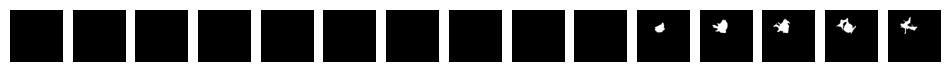

In [63]:
volume = np.stack(slices, axis=-1)

volume = volume.astype(np.float32) / np.max(volume)

print(f"Volume shape: {volume.shape}")

plt.figure(figsize=(12, 4))
for i in range(15):
    plt.subplot(1, 15, i + 1)
    plt.imshow(volume[:, :, i], cmap="gray")
    plt.axis("off")
plt.show()

In [75]:
def generate_mesh_for_id(unique_id, slices):
    volume = np.stack(slices, axis=-1)

    volume = volume.astype(np.float32) / np.max(volume)

    verts, faces, normals, values = measure.marching_cubes(volume, level=0.8)

    obj_filename = f"brain_model_{unique_id}.obj"
    save_as_obj(verts, faces, obj_filename)
    print(f"Mesh saved as {obj_filename}")

    mesh = trimesh.load(obj_filename)
    mesh.show()

In [76]:
def save_as_obj(vertices, faces, filename):
    with open(filename, 'w') as obj_file:
        for v in vertices:
            obj_file.write(f"v {v[0]} {v[1]} {v[2]}\n")

        for f in faces:
            obj_file.write(f"f {f[0] + 1} {f[1] + 1} {f[2] + 1}\n")

In [77]:
import trimesh


for id, slices in grouped_slices.items():
    print(f"Processing ID: {id} with {len(slices)} slices")
    generate_mesh_for_id(id, slices)


Processing ID: 4941 with 23 slices
Mesh saved as brain_model_4941.obj


In [78]:
mesh = trimesh.load("brain_model_4941.obj")
mesh.show()

In [90]:
!pip install opencv-python

^C
  Using cached opencv_python-4.10.0.84-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   ----

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
  File "C:\Users\Public\anaconda3\envs\env\lib\http\client.py", line 463, in read
    n = self.readinto(b)
  File "C:\Users\Public\anaconda3\envs\env\lib\http\client.py", line 507, in readinto
    n = self.fp.readinto(b)
  File "C:\Users\Public\anaconda3\envs\env\lib\socket.py", line 704, in readint

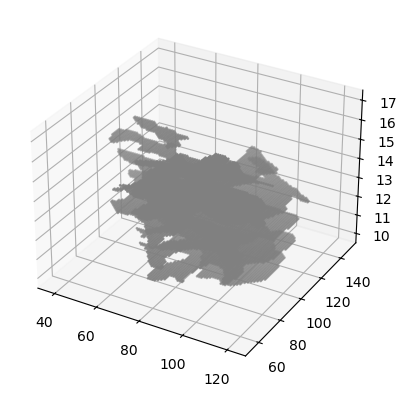

In [124]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def create_3d_object(image_paths):

    images = []
    for path in image_paths:
        img = cv2.imread(os.path.join(dataset_folder,"TCGA_CS_4941_19960909",path), cv2.IMREAD_GRAYSCALE)
        images.append(img)

    # Stack the images along the z-axis
    volume = np.stack(images, axis=-1)

    return volume

# Example usage:
file_list = natsorted([f for f in os.listdir(image_dir) if f.endswith('.tif') and f.find("_mask") > 0])
volume = create_3d_object(file_list)

# Visualize the 3D object using Matplotlib
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Assuming the volume is binary (black and white)
x, y, z = np.where(volume > 0)
ax.scatter(x, y, z, c='gray', s=1)

plt.show()


In [131]:
import meshlib.mrmeshpy as mr
import numpy as np
mask_stack = volume

# Create a 3D volume from the 2D masks
volume = mr.volume(mask_stack[0].shape[0], mask_stack[0].shape[1], len(mask_stack))
for i, mask in enumerate(mask_stack):
    volume.setVoxels(mask.astype(np.uint8), i)

# Extract the surface mesh using Marching Cubes
mesh = mr.gridToMesh(volume, isoValue=128)  # Adjust isoValue as needed

# Save the mesh to a file
mr.saveMesh(mesh, "output.stl")

AttributeError: module 'meshlib.mrmeshpy' has no attribute 'volume'

In [129]:
!pip install vtk

   ---------------------------------------- 0.0/58.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/58.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/58.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/58.4 MB ? eta -:--:--
   ---------------------------------------- 0.5/58.4 MB 1.2 MB/s eta 0:00:49
    --------------------------------------- 0.8/58.4 MB 1.3 MB/s eta 0:00:45
    --------------------------------------- 1.0/58.4 MB 1.1 MB/s eta 0:00:52
    --------------------------------------- 1.3/58.4 MB 1.2 MB/s eta 0:00:49
   - -------------------------------------- 1.6/58.4 MB 1.1 MB/s eta 0:00:52
   - -------------------------------------- 1.6/58.4 MB 1.1 MB/s eta 0:00:52
   - -------------------------------------- 1.8/58.4 MB 1.1 MB/s eta 0:00:54
   - -------------------------------------- 1.8/58.4 MB 1.1 MB/s eta 0:00:54
   - -------------------------------------- 2.1/58.4 MB 986.6 kB/s eta 0:00:58
   - --------------------

In [135]:
image_dir = os.path.join(dataset_folder,"TCGA_CS_4941_19960909")
file_list = natsorted([f for f in os.listdir(image_dir) if f.endswith('.tif')])
imgs =[]
for file in file_list:
    if file.find("_mask") >0:
        unique_id = file.split('_')[2]
    
        img_path = os.path.join(image_dir, file)
        img = io.imread(img_path)
    
        if img.ndim == 3 and img.shape[-1] == 3:
            img = rgb2gray(img)
    
        imgs.append(img)

In [136]:
print(imgs)

[array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8), array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8), array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8), array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8), array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0

In [140]:
import vtk

# Assuming you have a list of 2D masks as NumPy arrays
mask_stack = imgs

# Create a 3D image
image = vtk.vtkImageData()
image.SetDimensions(mask_stack[0].shape[0], mask_stack[0].shape[1], len(mask_stack))
image.AllocateScalars(vtk.VTK_UNSIGNED_CHAR, 1)

# Populate the image data
for i, mask in enumerate(mask_stack):
    for j, value in enumerate(mask.flatten()):
        image.SetScalarComponentFromDouble(j, i, i, value)
# Create a contour filter
contourFilter = vtk.vtkContourFilter()
contourFilter.SetInputData(image)
contourFilter.SetValue(0, 128)  # Adjust isovalue as needed

# Create a mapper and an actor
mapper = vtk.vtkPolyDataMapper()
mapper.SetInputConnection(contourFilter.GetOutputPort())

actor = vtk.vtkActor()
actor.SetMapper(mapper)

# Create a renderer and a render window
renderer = vtk.vtkRenderer()
renderWindow = vtk.vtkRenderWindow()
renderWindow.AddRenderer(renderer)

# Add the actor to the renderer
renderer.AddActor(actor)

# Render the scene
renderWindow.Render()
renderWindow.SetWindowName("3D Object from Masks")
renderWindow.Render()

# Optional: Save the mesh to a file
writer = vtk.vtkSTLWriter()
writer.SetInputConnection(contourFilter.GetOutputPort())
writer.SetFileName("output.stl")
writer.Write()

TypeError: SetScalarComponentFromDouble() takes exactly 5 arguments (4 given)

In [48]:
!pip install pyvista

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   ---- --------------------------

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
  File "C:\Users\Public\anaconda3\envs\env\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
  File "C:\Users\Public\anaconda3\envs\env\lib\http\client.py", line 463, in read
    n = self.readinto(b)
  File "C:\Users\Public\anaconda3\envs\env\lib\http\client.py", line 507, in readinto
    n = self.fp.readinto(b)
  File "C:\Users\Public\anaconda3\envs\env\lib\socket.py", line 704, in readint

(200, 256, 256)


c:\Users\public\anaconda3\envs\env\lib\site-packages\pyvista\jupyter\notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


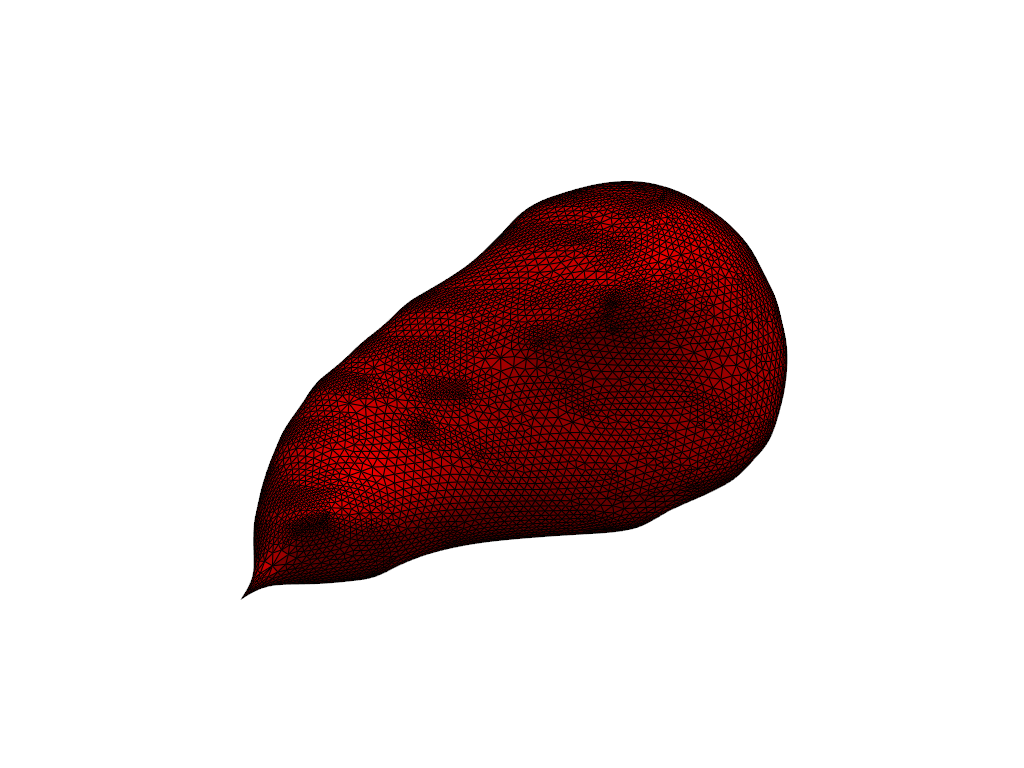

In [172]:
import pyvista as pv
import numpy as np
from pyvista import _vtk as vtk
import os
from vtk.util import numpy_support
import numpy as np
from PIL import Image

def load_image_stack(image_folder, image_format="tif"):
    image_files = [f for f in os.listdir(image_folder) if f.endswith(image_format) and f.find("_mask") > 0]*5
    image_files.sort() 

    img_example = Image.open(os.path.join(image_folder, image_files[0]))
    img_data = np.array(img_example)
    
    volume_data = np.zeros((len(image_files), img_data.shape[0], img_data.shape[1]), dtype=np.uint8)

    for i, image_file in enumerate(image_files):
        img = Image.open(os.path.join(image_folder, image_file))
        img_data = np.array(img)
        volume_data[i, :, :] = img_data

    return volume_data

def numpy_to_vtk_image(volume_data):
    depth, height, width = volume_data.shape
    vtk_image = vtk.vtkImageData()
    vtk_image.SetDimensions(width, height, depth)

    flat_data = volume_data.flatten()
    vtk_array = numpy_support.numpy_to_vtk(flat_data, deep=True, array_type=vtk.VTK_UNSIGNED_CHAR)

    vtk_image.GetPointData().SetScalars(vtk_array)

    return vtk_image

def extract_surface_from_volume(vtk_image):
    mc = vtk.vtkMarchingCubes()
    mc.SetInputData(vtk_image)
    mc.ComputeNormalsOn()
    mc.SetValue(0, 128) 
    mc.update()
    surface = pv.wrap(mc.GetOutput())
    edges = surface.extract_feature_edges()

    smoothed_surface = surface.smooth_taubin(n_iter=500, pass_band=0.005)
    pl = pv.Plotter()
    pl.add_mesh(smoothed_surface, color='red', show_edges=True)
    #pl.add_mesh(edges, color='red', line_width=1)
    pl.camera_position = 'yz'
    pl.show()
    
    smoothed_surface.save('output_mesh.obj')
    smoother = vtk.vtkSmoothPolyDataFilter()
    smoother.SetInputConnection(mc.GetOutputPort())
    smoother.SetNumberOfIterations(100)
    smoother.Update()
    """
    surf = pv.wrap(smoother.GetOutput())
    surf.clear_data()
    feature_edges = vtk.vtkFeatureEdges()
    feature_edges.SetInputConnection(smoother.GetOutputPort())
    feature_edges.BoundaryEdgesOn()
    feature_edges.Update()

    reconstruct_surface = vtk.vtkSurfaceReconstructionFilter()
    reconstruct_surface.SetInputConnection(feature_edges.GetOutputPort())
    reconstruct_surface.Update()
    
    append_filter = vtk.vtkAppendFilter()
    append_filter.AddInputConnection(smoother.GetOutputPort())
    append_filter.AddInputConnection(reconstruct_surface.GetOutputPort())
    append_filter.Update()
    """

    surface_mapper = vtk.vtkPolyDataMapper()
    mapper = vtk.vtkPolyDataMapper()  # Create a VTK mapper for the surface
    mapper.SetInputData(smoothed_surface) 
    surface_mapper.SetInputConnection(smoother.GetOutputPort())
    
    surface_actor = vtk.vtkActor()

    surface_actor.SetMapper(surface_mapper)

    return surface_actor

def render_3d_model(surface_actor):
    renderer = vtk.vtkRenderer()
    render_window = vtk.vtkRenderWindow()
    render_window.AddRenderer(renderer)

    render_window_interactor = vtk.vtkRenderWindowInteractor()
    render_window_interactor.SetRenderWindow(render_window)

    renderer.AddActor(surface_actor)

    renderer.SetBackground(0.1, 0.1, 0.1) 

    render_window.Render()
    render_window_interactor.Start()


image_folder = os.path.join(dataset_folder,"TCGA_DU_7309_19960831")

volume_data = load_image_stack(image_folder)
print(volume_data.shape)
vtk_image = numpy_to_vtk_image(volume_data)

surface_actor = extract_surface_from_volume(vtk_image)

#render_3d_model(surface_actor)

In [2]:
import pyvista as pv

(119.85042572021484, 152.78201293945312, 43.5485954284668, 101.94379425048828, 60.04695129394531, 105.2379379272461)


c:\Users\public\anaconda3\envs\env\lib\site-packages\pyvista\jupyter\notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


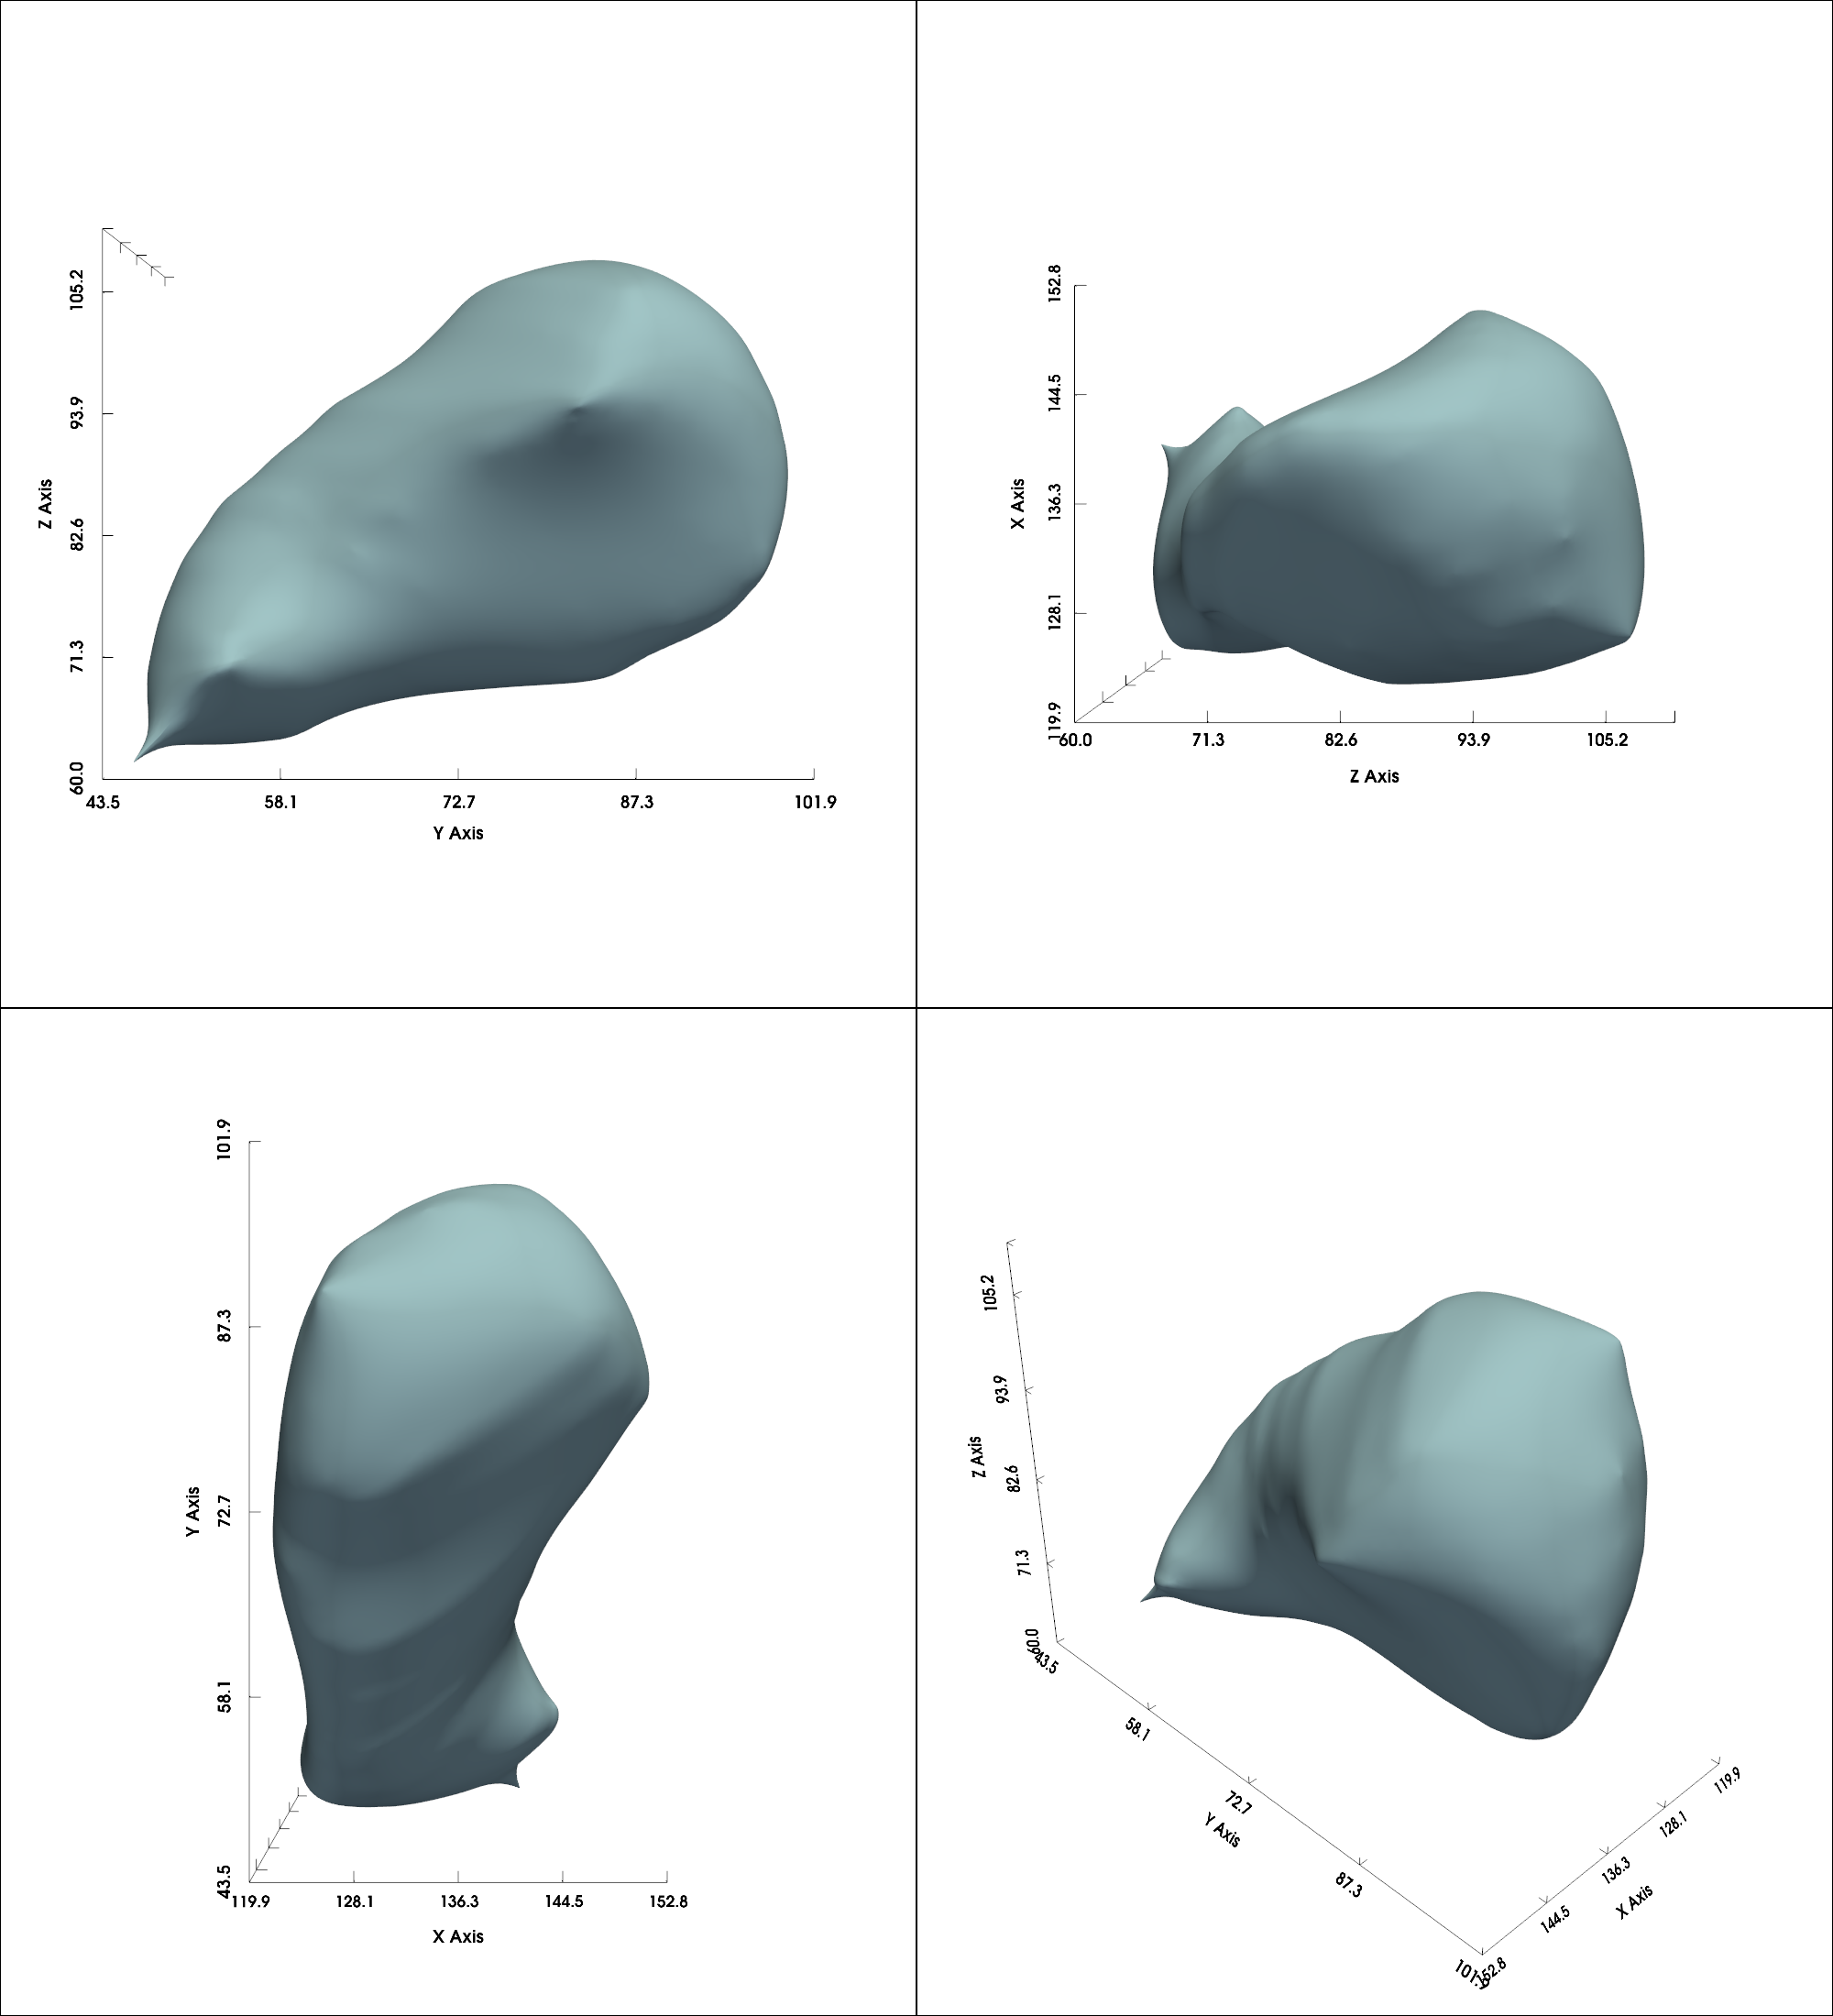

In [36]:
mesh = pv.read("output_mesh.obj")
print(mesh.bounds)
plotter = pv.Plotter(shape=(2, 2),window_size=(2000, 2200))
plotter.subplot(0, 0)
plotter.add_mesh(mesh, show_edges=False,smooth_shading=True, split_sharp_edges=True)
plotter.camera_position = 'yz'
plotter.show_bounds(location='outer',font_size=14)
plotter.subplot(0, 1)
plotter.add_mesh(mesh, show_edges=False,smooth_shading=True, split_sharp_edges=True)
#pl.add_mesh(edges, color='red', line_width=1)
plotter.camera_position = 'zx'
plotter.show_bounds(location='front',font_size=14)
plotter.subplot(1, 0)
plotter.add_mesh(mesh, show_edges=False,smooth_shading=True, split_sharp_edges=True)
#pl.add_mesh(edges, color='red', line_width=1)
plotter.camera_position = 'xy'
plotter.show_bounds(location='front',font_size=14)
plotter.subplot(1, 1)
plotter.add_mesh(mesh, show_edges=False,smooth_shading=True, split_sharp_edges=True)
#pl.add_mesh(edges, color='red', line_width=1)
plotter.camera_position = 'iso'
plotter.show_bounds(location='outer',font_size=14)
plotter.show()
plotter.save_graphic("test.pdf")

c:\Users\public\anaconda3\envs\env\lib\site-packages\pyvista\jupyter\notebook.py:37: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


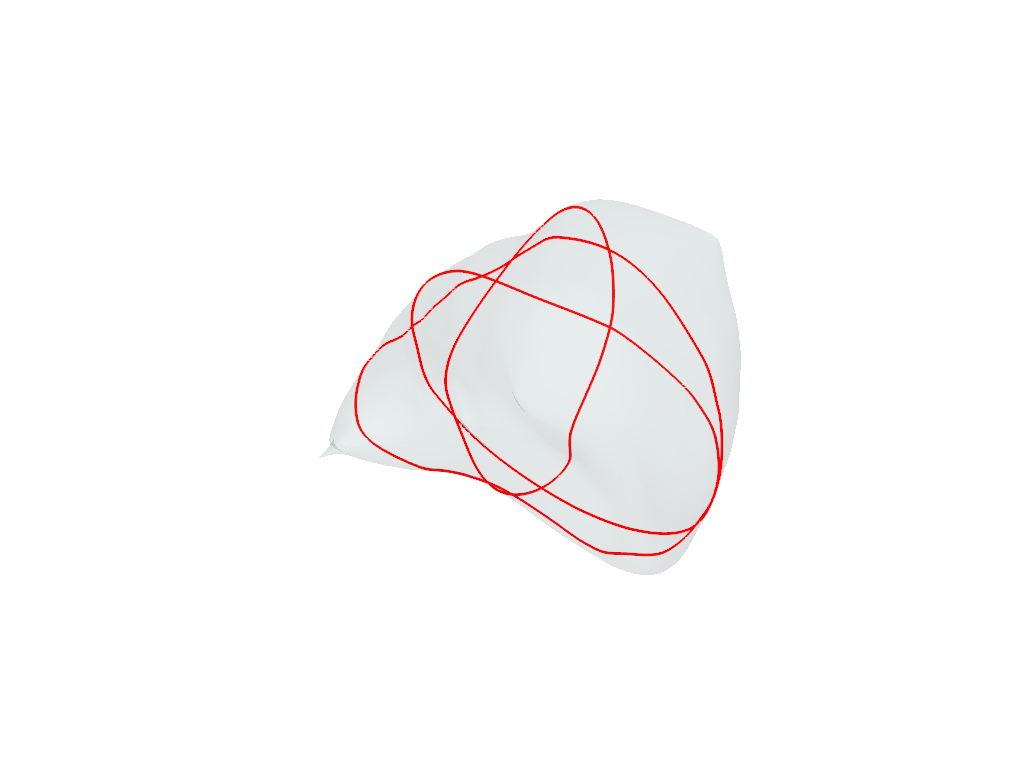

In [62]:
import matplotlib.pyplot as plt
import numpy as np

import pyvista as pv
from pyvista import examples
meshh = pv.read("output_mesh.obj")
slices = meshh.slice_orthogonal()
slice_plane = meshh.slice(normal='z',origin=(0,0,0))
plt = pv.Plotter()
plt.add_mesh(meshh,opacity=0.1,color="lightblue")
plt.add_mesh(slices,color="red",line_width=3)
plt.show()

In [ ]:
!pip install vedo

In [72]:
from vedo import Mesh, Plane, show

# Load the 3D object
mesh = Mesh("output_mesh.obj").c("white")  # Normalize and set color

# Define the slicing plane
plane_origin = (0, 0, 0)  # Origin of the slicing plane
plane_normal = (0, 0, 1)  # Normal vector of the slicing plane

# Slice the mesh
sliced_mesh = mesh.slice(origin=plane_origin, normal=plane_normal)  # Slice the mesh

# Visualize the original mesh and the slice
from vedo import show

# You don't need the Plotter object if in Jupyter
show([mesh, sliced_mesh], interactive=True,zoo)



AttributeError: 'Mesh' object has no attribute 'clip'

In [ ]:
"""Manual capping of a mesh"""
from vedo import *

def capping(amsh, bias=0, invert=False, res=50):

    bn =  amsh.boundaries().join(reset=True)

    pln = fit_plane(bn)
    cp = [pln.closest_point(p) for p in bn.vertices]
    pts = Points(cp)

    if invert is None:
        cutm = amsh.clone().cut_with_plane(origin=pln.center, normal=pln.normal)
        invert = cutm.npoints > amsh.npoints

    pts2 = pts.clone().reorient(pln.normal, [0,0,1]).project_on_plane('z')
    msh2 = pts2.generate_mesh(invert=invert, mesh_resolution=res)

    source = pts2.vertices.tolist()
    target = bn.vertices.tolist()
    printc(f"..warping {len(source)} points")
    msh3 = msh2.clone().warp(source, target, mode='3d')

    if not invert:
        bias *= -1
        msh3.reverse()

    if bias:
        newpts = []
        for p in msh3.vertices:
            q = bn.closest_point(p)
            d = mag(p-q)
            newpt = p + d * pln.normal * bias
            newpts.append(newpt)
        msh3.points(newpts)
    return msh3


msh = Mesh("output_mesh.obj").c('orange5').bc('purple7').lw(1)

# mcap = msh.cap()  # automatic
mcap = capping(msh, invert=True)

merged_msh = merge(msh, mcap).clean().smooth()
merged_msh.subsample(0.0001).wireframe(False)  # merge duplicate points
printc("merged_msh is closed:", merged_msh.is_closed())

show([[msh, __doc__],
      [merged_msh, merged_msh.boundaries()]],
      N=2, axes=1, elevation=-40,
).close()

In [ ]:
"""Form a surface mesh by joining contour lines"""
from vedo import Circle, Ribbon, merge, show
from vedo import dataurl, Plotter, Mesh, Sphere

cs = []
for i in range(-10, 10):
    r = 10 / (i * i + 10)
    c = Circle(r=r).rotate_y(i*2).z(i/10).x(i/20)
    c.linewidth(3).linecolor('blue5')
    cs.append(c)

# create the mesh by merging the ribbon strips
rbs = []
for i in range(len(cs) - 1):
    rb = Ribbon(cs[i], cs[i+1], closed=True, res=(150,5))
    rbs.append(rb)
mesh = merge(rbs).clean().cap().color('limegreen')

cs.append(__doc__)
cutmesh = Sphere().y(-0.4).scale(0.4).wireframe().alpha(0.1)

msh2 = mesh.clone().cut_with_mesh(cutmesh)
redcap = msh2.cap(return_cap=True).color("r4")

plt = Plotter(N=2, axes=1)
plt.at(0).show(mesh, cutmesh, __doc__)
plt.at(1).show(msh2, redcap, viewup="z")


In [4]:
"""Form a surface mesh by joining contour lines"""
from vedo import Circle, Ribbon, merge, show

cs = []
for i in range(-10, 10):
    r = 10 / (i * i + 10)
    c = Circle(r=r).rotate_y(i*2).z(i/10).x(i/20)
    c.linewidth(3).linecolor('blue5')
    cs.append(c)

# create the mesh by merging the ribbon strips
rbs = []
for i in range(len(cs) - 1):
    rb = Ribbon(cs[i], cs[i+1], closed=True, res=(150,5))
    rbs.append(rb)
mesh = merge(rbs).clean().cap().color('limegreen')

cs.append(__doc__)

show([cs, mesh], N=2, axes=1, elevation=-40, bg2='lb').close()